# MLP (Multi-level perceptron)
`6 inputs -> [64 neurons] -> [64 neurons] -> 1 output`

In [1]:
import sys
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

sys.path.append(str(Path().resolve().parent/"src"))
from features import add_geometry_features
from evaluation import add_results, plot_pred_vs_true


torch.manual_seed(0) # for reproducability
results = {}

---
#### Functions

In [2]:
def prepare_data(train_df, test_df, features, targets):
    # random_state remains 0 to ensure every model is trained on the exact same data
    x_t, x_v, y_t, y_v = train_test_split(train_df[features], train_df[targets], test_size=0.2, random_state=0)

    # Get scalars:
    x_scalar = StandardScaler().fit(x_t)
    y_scalar = StandardScaler().fit(y_t)

    # Apply Scalars:
    x_train = torch.tensor(x_scalar.transform(x_t),dtype=torch.float32)
    x_val = torch.tensor(x_scalar.transform(x_v),dtype=torch.float32)
    x_test = torch.tensor(x_scalar.transform(test_df[features]),dtype=torch.float32)
    y_train = torch.tensor(y_scalar.transform(y_t),dtype=torch.float32)
    y_val = torch.tensor(y_scalar.transform(y_v),dtype=torch.float32)
    y_test = torch.tensor(y_scalar.transform(test_df[targets]),dtype=torch.float32)

    return {
        "x_train":x_train,
        "y_train":y_train,
        "x_test":x_test,
        "y_test":y_test,
        "x_val":x_val,
        "y_val":y_val,
        "x_scalar":x_scalar,
        "y_scalar":y_scalar
    }

In [3]:
def build_model(n_inputs, n_outputs, hidden=64):
    model = nn.Sequential(
    nn.Linear(n_inputs,hidden),nn.ReLU(),
    nn.Linear(hidden,hidden),nn.ReLU(),
    nn.Linear(hidden,n_outputs))
    
    return model

In [4]:
def train_model(model,data,epochs,lr,batch_size):

    # Parameters 
    loss_fn = nn.MSELoss()
    optimiser = torch.optim.Adam(model.parameters(),lr=lr)

    batches = DataLoader(
        TensorDataset(data["x_train"],data["y_train"]),
        batch_size=batch_size,
        shuffle=True)


    train_losses = []
    val_losses = []
    # Training Loop
    for epoch in range(epochs):
        batch_losses=[]
        for x_batch, y_batch in batches:
            # Predict from x
            pred = model(x_batch)
            # measure error
            loss = loss_fn(pred,y_batch)
            # clear previous gradients
            optimiser.zero_grad()
            # backpropagation
            loss.backward()
            # nudge the weights
            optimiser.step()

            batch_losses.append(loss.item())
        # record training and validation loss
        train_losses.append(np.mean(batch_losses))

        model.eval()
        with torch.no_grad():
            val_losses.append(loss_fn(model(data["x_val"]),data["y_val"]).item())
        model.train()

    
    return train_losses, val_losses

In [5]:
def predict(model,x_test,y_scalar):
    model.eval()
    with torch.no_grad():
        pred = model(x_test)
    pred = y_scalar.inverse_transform(pred)

    return pred

In [6]:
def run_experiment(features, targets,train_df, test_df,results,model_name,seed=0,batch_size = 32,num_epochs = 100,learning_rate = 0.001):
    torch.manual_seed(seed)

    # prepare data
    data = prepare_data(train_df, test_df, features, targets)
    # build model
    model = build_model(len(features), len(targets))
    # train the model
    train_l, val_l = train_model(model, data, num_epochs, learning_rate, batch_size)
    # predict from model
    pred = predict(model,data["x_test"],data["y_scalar"])
    # evaluate model

    # pred has one column per target, in the same order as `targets`
    kwargs = {}
    for i, target in enumerate(targets):
        kwargs[f"{target}_true"] = test_df[target]
        kwargs[f"{target}_pred"] = pred[:, i]
    results = add_results(results, model_name, **kwargs)
    
    # return results, predicted values, train_1osses, val_losses
    return results, pred, train_l, val_l
    

---

In [7]:
# Load and Prepare the Data into a dataframe
CSV_PATH = Path().resolve().parent/"data"/"processed"/"airfrans_coefficients.csv"
df = pd.read_csv(CSV_PATH)
df = add_geometry_features(df)

# Split on full set
train_df = df.loc[df["split_full"]=="train"]
test_df = df.loc[df["split_full"]=="test"]#

FEATURES = ["angleOfAttack","Re","max_camber","camber_pos","thickness","reflex"]
TARGETS = ["cl"]

In [8]:
# Building the CL only model
results, pred, cl_train_loss, cl_val_loss = run_experiment(FEATURES, TARGETS, train_df, test_df, results, "cl_only_mlp")


--- Cl (coefficient of Lift) ---
MAE: 0.0234237852857956
RMSE: 0.03059407730846717
R^2: 0.9972102746061016


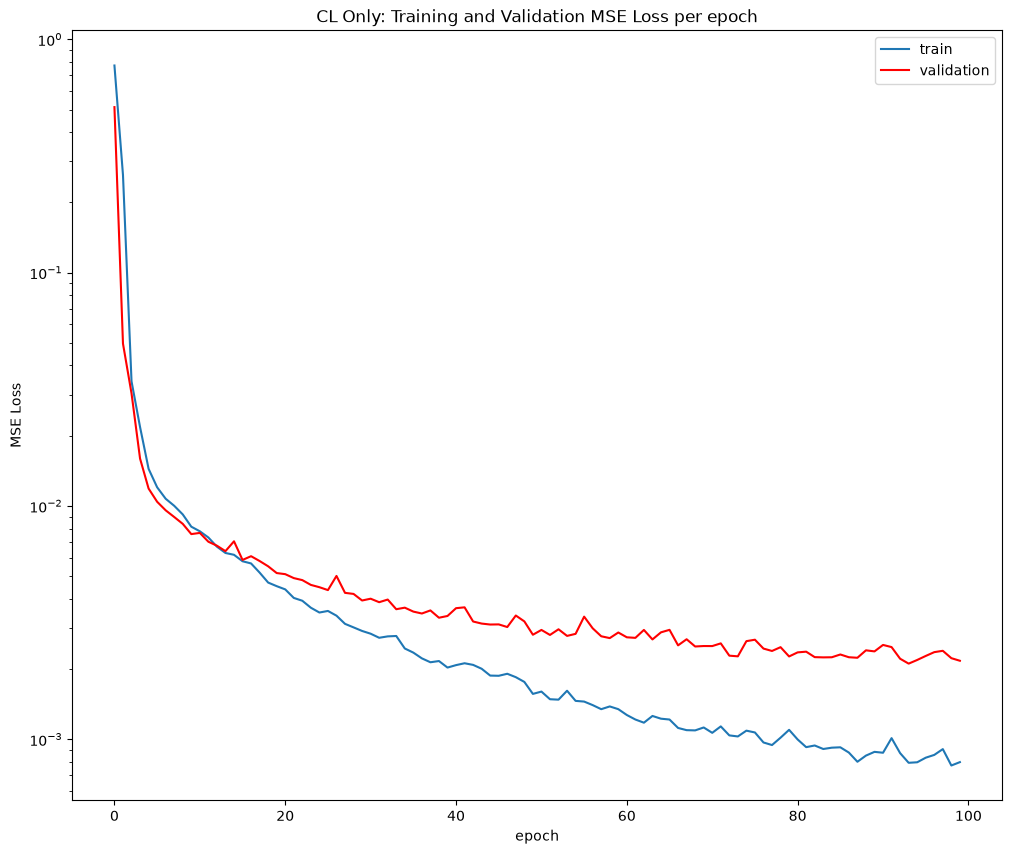

In [9]:
# Plot the loss functions over time
fig, ax = plt.subplots(figsize=(12,10))
ax.plot(cl_train_loss,label="train")
ax.plot(cl_val_loss,label="validation",color="RED")
ax.set_title("CL Only: Training and Validation MSE Loss per epoch")
ax.set_ylabel("MSE Loss")
ax.set_xlabel("epoch")
ax.set_yscale("log")
ax.legend()

Notes from the above graph: There is clear improvement with rapid improvements from epoch 0-10. From epoch 15 onwards the two lines for training and validation begin to split as the model begins to overfit, however the validation is still improving.

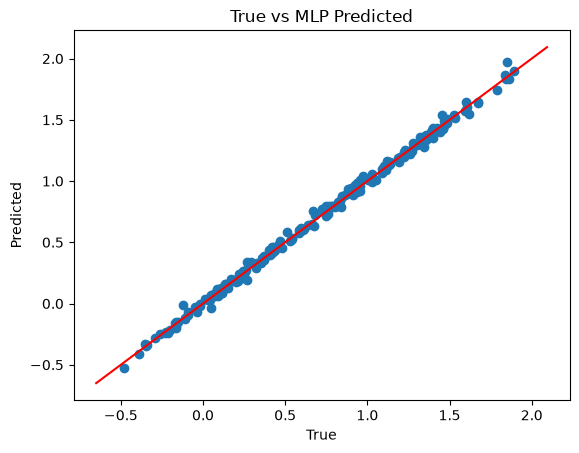

In [10]:

fig, ax = plt.subplots()
plot_pred_vs_true(ax,test_df["cl"],pred, "True vs MLP Predicted")

In [11]:
print(results)

{'cl_only_mlp': {'cl_mae': 0.0234237852857956, 'cl_rmse': 0.03059407730846717, 'cl_r2': 0.9972102746061016}}



--- Cl (coefficient of Lift) ---
MAE: 0.024751389189170307
RMSE: 0.03179085592944985
R^2: 0.9969877488562205
--- Cd (coefficient of Drag) ---
MAE: 0.0006229073992929831
RMSE: 0.0009007135216041428
R^2: 0.9636770950507925

--- Cl (coefficient of Lift) ---
MAE: 0.02859613106145743
RMSE: 0.03867348560406137
R^2: 0.9955422740163219
--- Cd (coefficient of Drag) ---
MAE: 0.0006254782729206327
RMSE: 0.0009624561005770159
R^2: 0.9585266546041354


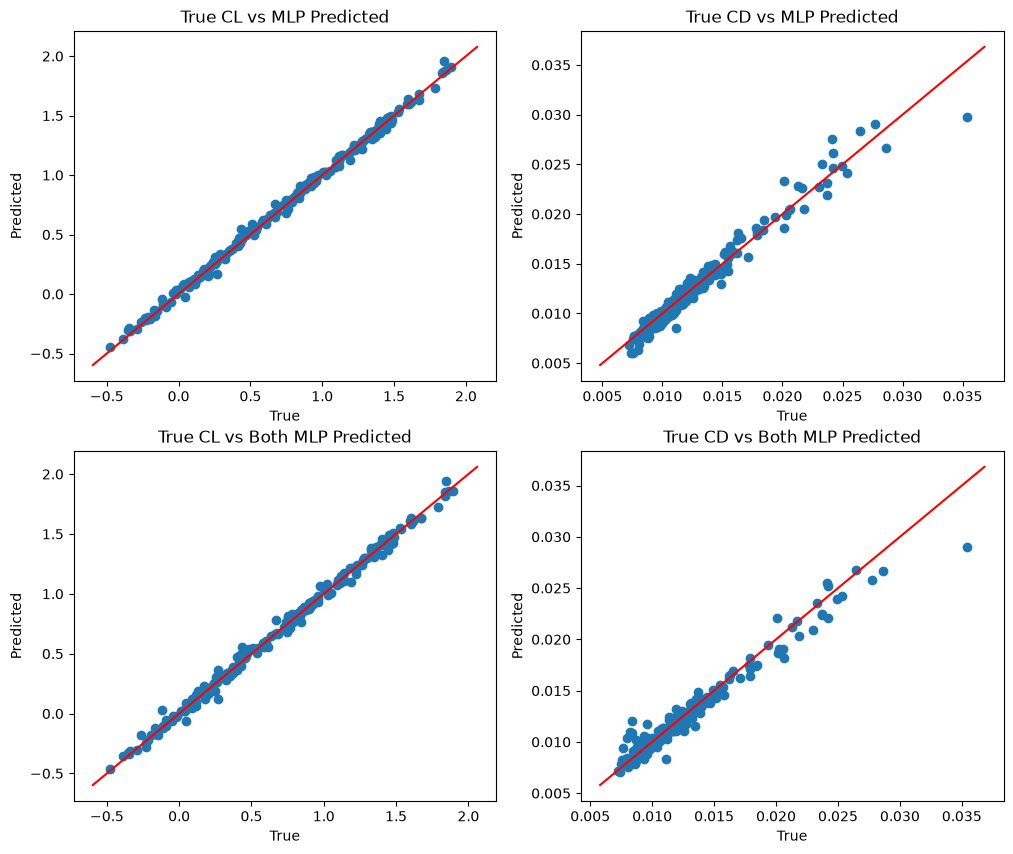

In [12]:
# Creating other models
results, cl_pred, cl_2_train_loss, cl_2_val_loss = run_experiment(FEATURES, ["cl"], train_df, test_df, results, "cl_only_mlp_alt_seed",1) # Checking model with another seed
results, cd_pred, cd_train_loss, cd_val_loss = run_experiment(FEATURES, ["cd"], train_df, test_df, results, "cd_only_mlp")
results, both_pred, both_train_loss, both_val_loss = run_experiment(FEATURES, ["cl","cd"],train_df, test_df, results, "cl_cd_mlp")

# Plot the results for all
fig, ax = plt.subplots(2,2,figsize=(12,10))
plot_pred_vs_true(ax[0][0],test_df["cl"],cl_pred, "True CL vs MLP Predicted")
plot_pred_vs_true(ax[0][1],test_df["cd"],cd_pred, "True CD vs MLP Predicted")
plot_pred_vs_true(ax[1][0],test_df["cl"],both_pred[:,0], "True CL vs Both MLP Predicted")
plot_pred_vs_true(ax[1][1],test_df["cd"],both_pred[:,1], "True CD vs Both MLP Predicted")

In [ ]:
# Further Testing for seed
seed_results = {}
for i in range(10,100,10):
    print(f"--- {i} ---")
    # run models with seed i given
    seed_results, cl_pred, cl_2_train_loss, cl_2_val_loss = run_experiment(FEATURES, ["cl"], train_df, test_df, seed_results, "cl_only_mlp_"+str(i),i)
    seed_results, cd_pred, cd_train_loss, cd_val_loss = run_experiment(FEATURES, ["cd"], train_df, test_df, seed_results, "cd_only_mlp_"+str(i),i)
    seed_results, both_pred, both_train_loss, both_val_loss = run_experiment(FEATURES, ["cl","cd"],train_df, test_df, seed_results, "cl_cd_mlp_"+str(i),i)

table = pd.DataFrame(seed_results).T
table["setup"] = table.index.str.rsplit("_", n=1).str[0]
summary = table.groupby("setup").agg(["mean", "std"])
print(summary)

--- 10 ---

--- Cl (coefficient of Lift) ---
MAE: 0.019156296172228436
RMSE: 0.02560555047600641
R^2: 0.9980458631708111
--- Cd (coefficient of Drag) ---
MAE: 0.0004557291921421938
RMSE: 0.0007248385786087539
R^2: 0.9764771570289555

--- Cl (coefficient of Lift) ---
MAE: 0.02638298671089517
RMSE: 0.034070677967050156
R^2: 0.9965402215651042
--- Cd (coefficient of Drag) ---
MAE: 0.0005249233306486123
RMSE: 0.0007975777917512337
R^2: 0.9715191258528814
--- 20 ---

--- Cl (coefficient of Lift) ---
MAE: 0.02337663376001556
RMSE: 0.03166805423076405
R^2: 0.9970109753534837
--- Cd (coefficient of Drag) ---
MAE: 0.0005610750697760151
RMSE: 0.0008645809200826742
R^2: 0.9665328674683744

--- Cl (coefficient of Lift) ---
MAE: 0.02900534441752285
RMSE: 0.03726447255378586
R^2: 0.9958611785307755
--- Cd (coefficient of Drag) ---
MAE: 0.0005234020530289052
RMSE: 0.0008568394768101944
R^2: 0.9671295125838968
--- 30 ---

--- Cl (coefficient of Lift) ---
MAE: 0.021331406779519817
RMSE: 0.0287217864759

From the above the std are generally low suggesting that the seed has a tiny effect in the outcome and performance of the CL model. However for CD, the std is much larger than that of CD (0.006)

In [18]:
print(pd.DataFrame(results))

         cl_only_mlp  cl_only_mlp_alt_seed  cd_only_mlp  cl_cd_mlp
cl_mae      0.023424              0.024751          NaN   0.028596
cl_rmse     0.030594              0.031791          NaN   0.038673
cl_r2       0.997210              0.996988          NaN   0.995542
cd_mae           NaN                   NaN     0.000623   0.000625
cd_rmse          NaN                   NaN     0.000901   0.000962
cd_r2            NaN                   NaN     0.963677   0.958527


From the results above, the model performance is not majorly dependent on the seed given (0.9972 on one, 0.9969 on another with mean being 0.997 with a std of 0.0005). It also appears, for these neural networks, they benefit from one per result (CL/CD) as the model with them combined does have a reduced r2 scores (0.9955 vs 0.9972 for CL, 0.9585 vs 0.9636 for CD). In terms of overall performance against the other methods the individual MLPs' are the new best performing for both CL and CD